In [1]:
from tensorflow.keras.datasets import cifar10

# Загрузка данных CIFAR-10
(x_train, y_train), (x_test, y_test) = cifar10.load_data()
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

print("Форма обучающего набора данных:", x_train.shape)
print("Форма тестового набора данных:", x_test.shape)


170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 151s 1us/step
Форма обучающего набора данных: (50000, 32, 32, 3)
Форма тестового набора данных: (10000, 32, 32, 3)


In [2]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

x_train_sub, _, y_train_sub, _ = train_test_split(x_train, y_train, train_size=5000, stratify=y_train, random_state=42)
x_train_sub_flat = x_train_sub.reshape(5000, -1)
x_test_flat = x_test.reshape(x_test.shape[0], -1)

#1
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(x_train_sub_flat, y_train_sub.ravel())
#2
svm = SVC(kernel='linear', C=1.0, random_state=42)
svm.fit(x_train_sub_flat, y_train_sub.ravel())

y_pred_knn = knn.predict(x_test_flat)
y_pred_svm = svm.predict(x_test_flat)

knn_accuracy = accuracy_score(y_test, y_pred_knn)
svm_accuracy = accuracy_score(y_test, y_pred_svm)

print(f"Точность модели KNN: {knn_accuracy:.4f}")
print(f"Точность модели SVM: {svm_accuracy:.4f}")


Точность модели KNN: 0.2795
Точность модели SVM: 0.2992


In [10]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.utils import to_categorical

x_train_flat = x_train.reshape(x_train.shape[0], -1)
x_test_flat = x_test.reshape(x_test.shape[0], -1)
y_train_categorical = to_categorical(y_train, num_classes=10)
y_test_categorical = to_categorical(y_test, num_classes=10)

# Создание модели MLP
model_mlp = Sequential([
    Dense(512, activation='relu', input_shape=(x_train_flat.shape[1],)),
    Dense(256, activation='relu'),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

model_mlp.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model_mlp.fit(x_train_flat, y_train_categorical, epochs=10, batch_size=64, validation_data=(x_test_flat, y_test_categorical))

test_loss_mlp, test_accuracy_mlp = model_mlp.evaluate(x_test_flat, y_test_categorical)
print(f"Точность модели MLP на тестовой выборке: {test_accuracy_mlp:.4f}")


Epoch 1/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 19s 22ms/step - accuracy: 0.2696 - loss: 2.0127 - val_accuracy: 0.3941 - val_loss: 1.7249
Epoch 2/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 17s 22ms/step - accuracy: 0.3882 - loss: 1.6994 - val_accuracy: 0.4019 - val_loss: 1.6485
Epoch 3/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 17s 22ms/step - accuracy: 0.4256 - loss: 1.6019 - val_accuracy: 0.4385 - val_loss: 1.5456
Epoch 4/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 17s 22ms/step - accuracy: 0.4496 - loss: 1.5388 - val_accuracy: 0.4604 - val_loss: 1.5197
Epoch 5/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 17s 21ms/step - accuracy: 0.4693 - loss: 1.4937 - val_accuracy: 0.4692 - val_loss: 1.4807
Epoch 6/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 17s 22ms/step - accuracy: 0.4802 - loss: 1.4603 - val_accuracy: 0.4731 - val_loss: 1.4908
Epoch 7/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 17s 22ms/step - accuracy: 0.4935 - loss: 1.4184 - val_accuracy: 0.4498 - val_loss: 1.5227
Epoch 8/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 17s 22ms/step - accuracy: 0.5040 - loss: 1.3864 - 

In [11]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.utils import to_categorical

y_train_categorical = to_categorical(y_train, num_classes=10)
y_test_categorical = to_categorical(y_test, num_classes=10)

# Создание модели CNN
model_cnn = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

model_cnn.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model_cnn.fit(x_train, y_train_categorical, epochs=10, batch_size=64, validation_data=(x_test, y_test_categorical))

test_loss_cnn, test_accuracy_cnn = model_cnn.evaluate(x_test, y_test_categorical)


Epoch 1/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 15s 18ms/step - accuracy: 0.3504 - loss: 1.7634 - val_accuracy: 0.5413 - val_loss: 1.2717
Epoch 2/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 14s 17ms/step - accuracy: 0.5721 - loss: 1.2087 - val_accuracy: 0.5975 - val_loss: 1.1240
Epoch 3/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 14s 18ms/step - accuracy: 0.6378 - loss: 1.0348 - val_accuracy: 0.6366 - val_loss: 1.0457
Epoch 4/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 14s 18ms/step - accuracy: 0.6799 - loss: 0.9176 - val_accuracy: 0.6788 - val_loss: 0.9257
Epoch 5/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 14s 17ms/step - accuracy: 0.7088 - loss: 0.8363 - val_accuracy: 0.6593 - val_loss: 1.0022
Epoch 6/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 13s 17ms/step - accuracy: 0.7392 - loss: 0.7618 - val_accuracy: 0.7099 - val_loss: 0.8432
Epoch 7/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 14s 17ms/step - accuracy: 0.7597 - loss: 0.6863 - val_accuracy: 0.7044 - val_loss: 0.8567
Epoch 8/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 14s 18ms/step - accuracy: 0.7779 - loss: 0.6415 - 

In [13]:
print(f"Точность модели MLP на тестовой выборке: {test_accuracy_mlp:.4f}")
print(f"Точность модели KNN: {knn_accuracy:.4f}")
print(f"Точность модели SVM: {svm_accuracy:.4f}")
print(f"Точность модели CNN на тестовой выборке: {test_accuracy_cnn:.4f}")

Точность модели MLP на тестовой выборке: 0.4880
Точность модели KNN: 0.2795
Точность модели SVM: 0.2992
Точность модели CNN на тестовой выборке: 0.7347


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step


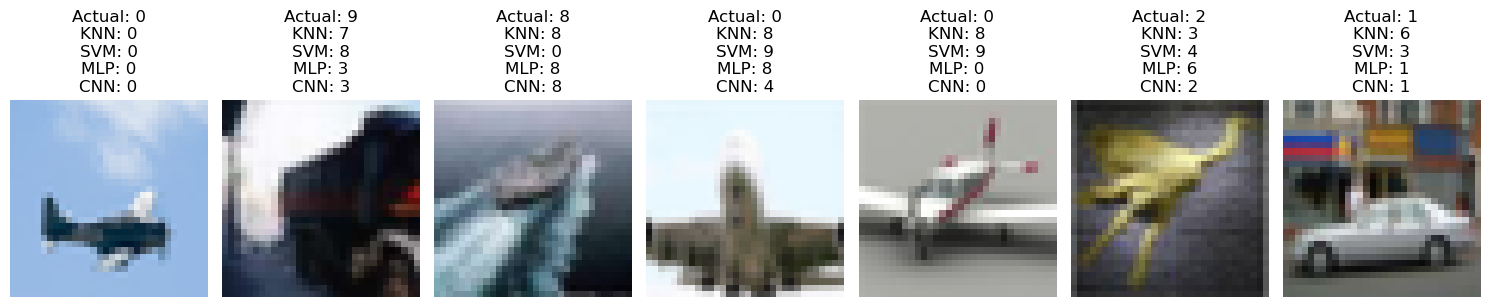

In [20]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import accuracy_score

# Предсказания на тестовых данных для MLP и CNN
y_pred_mlp = model_mlp.predict(x_test_flat)
y_pred_mlp_classes = np.argmax(y_pred_mlp, axis=1)

y_pred_cnn = model_cnn.predict(x_test)
y_pred_cnn_classes = np.argmax(y_pred_cnn, axis=1)

num_images = 7
random_indices = np.random.choice(x_test.shape[0], num_images, replace=False)

# Визуализация результатов
plt.figure(figsize=(15, 15))
for i, idx in enumerate(random_indices):
    plt.subplot(1, num_images, i+1)
    plt.imshow(x_test[idx])
    plt.axis('off')
    
    #Легенда
    actual_label = y_test[idx][0]
    knn_label = y_pred_knn[idx]
    svm_label = y_pred_svm[idx]
    mlp_label = y_pred_mlp_classes[idx]
    cnn_label = y_pred_cnn_classes[idx]   
    plt.title(f"Actual: {actual_label}\nKNN: {knn_label}\nSVM: {svm_label}\nMLP: {mlp_label}\nCNN: {cnn_label}")

plt.tight_layout()
plt.show()
